# SFT

In [ ]:
import datasets
ds = datasets.Dataset.from_json('/Users/christine/Downloads/cs224r-Default-Project/sft_trainer/sft_qwen05b_lr5e-5_ep6_best.json')
ds

Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['prompt', 'target', 'nums', 'ground_truth', 'response', 'scores'],
    num_rows: 50
})

In [2]:
import os
def map_fn(example):
    example['is_correct'] = [x==1.0 for x in example['scores']]
    return example

ds = ds.map(map_fn, num_proc=os.cpu_count())
ds

Map (num_proc=8):   0%|          | 0/50 [00:00<?, ? examples/s]

Dataset({
    features: ['prompt', 'target', 'nums', 'ground_truth', 'response', 'scores', 'is_correct'],
    num_rows: 50
})

In [3]:
import numpy as np
from scipy.special import comb
from tqdm import tqdm

def pass_at_k(n, c, k):
    if n - c < k:
        return 1.0
    return 1.0 - np.prod(1.0 - k / np.arange(n - c + 1, n + 1))

In [4]:
def calculate_pass_at_k_corrected(correctness_matrix):
    n_problems, n_samples = correctness_matrix.shape
    pass_at_k_values = []
    
    for k in range(1, n_samples + 1):
        pass_at_k_per_problem = []
        
        for problem_idx in range(n_problems):
            correct_samples = np.sum(correctness_matrix[problem_idx])
            
            pass_k = pass_at_k(n_samples, correct_samples, k)
            pass_at_k_per_problem.append(pass_k)
        
        avg_pass_at_k = np.mean(pass_at_k_per_problem)
        pass_at_k_values.append(avg_pass_at_k)
    
    return np.array(pass_at_k_values)

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FuncFormatter

correctness_matrix = np.array(ds["is_correct"])
pass_at_k_values = np.asarray(calculate_pass_at_k_corrected(correctness_matrix))

print(pass_at_k_values)

[0.29125    0.4465     0.53825    0.59664835 0.63587454 0.66344655
 0.68368182 0.69916239 0.71146154 0.72155345 0.73005952 0.7373956
 0.74385714 0.74966667 0.755      0.76      ]


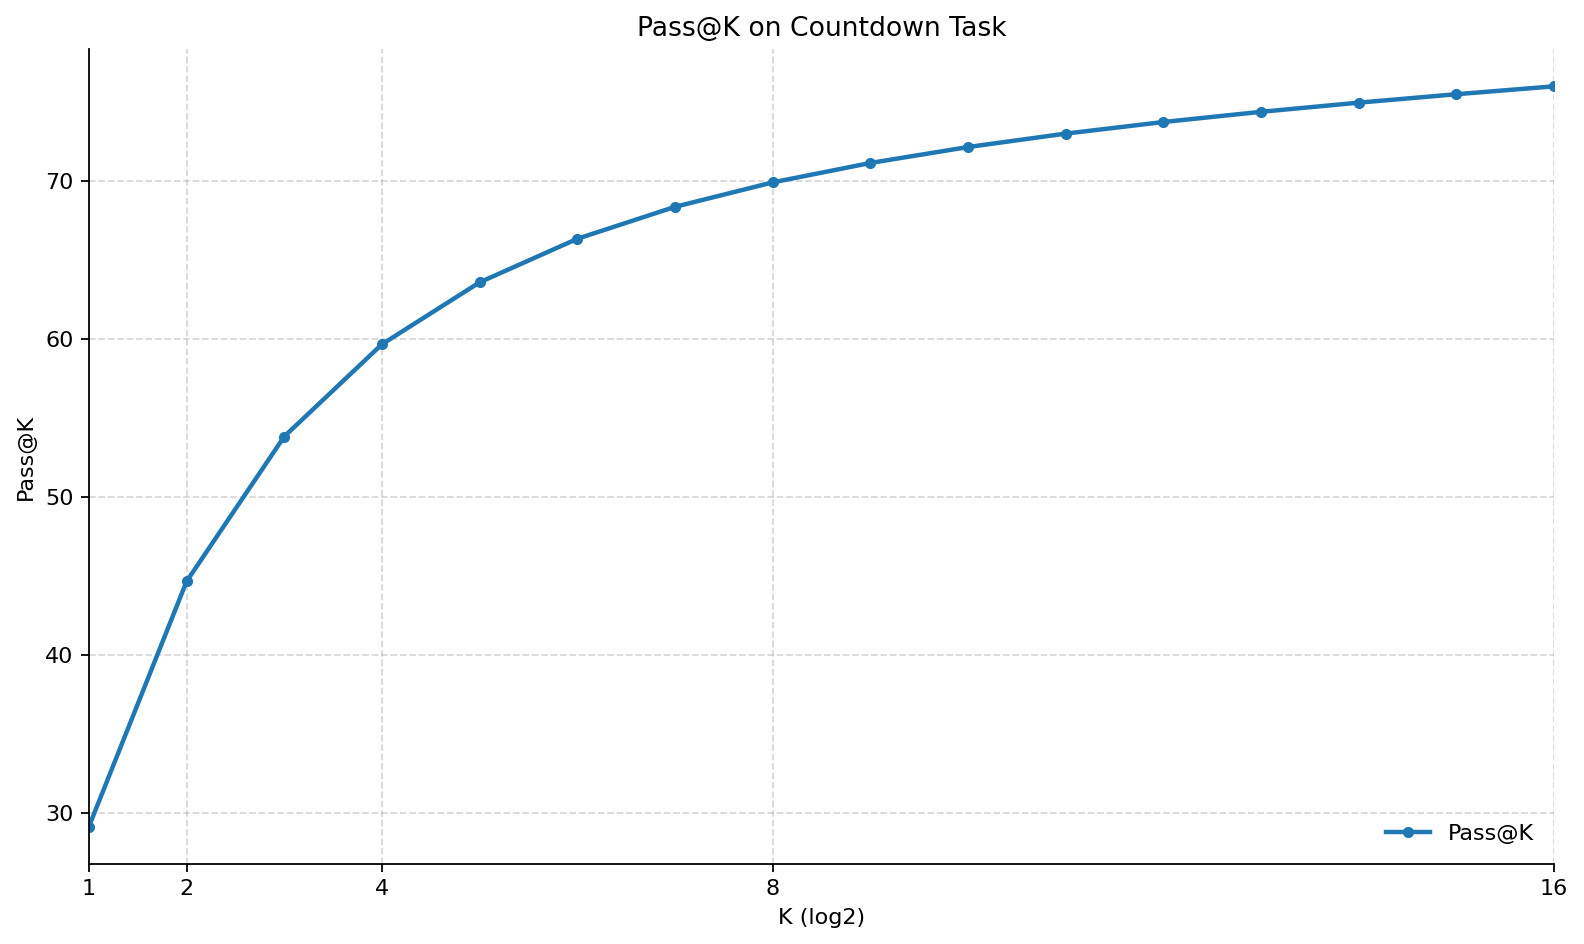

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter

k = np.arange(1, len(pass_at_k_values) + 1)

# Create a figure for the plot
fig, ax = plt.subplots(figsize=(10, 6), dpi=160)

ax.plot(k, pass_at_k_values * 100, marker="o", markersize=4, linewidth=2, label="Pass@K")

ax.set_xlabel("K (log2)")
ax.set_ylabel("Pass@K")
ax.set_title("Pass@K on Countdown Task")
ax.set_xlim(1, k[-1])

major_ticks = [t for t in [1, 2, 4, 8, 16] if t <= k[-1]]
ax.xaxis.set_major_locator(FixedLocator(major_ticks))
ax.set_xticklabels([str(t) for t in major_ticks])

ax.grid(True, which="major", linestyle="--", linewidth=0.8, alpha=0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

# Milestone: IPO and RLOO

In [3]:
import datasets
import numpy as np
import os
from matplotlib.ticker import FixedLocator

def load_passk(path):
    d = datasets.Dataset.from_json(path)
    d = d.map(lambda ex: {"is_correct": [x == 1.0 for x in ex["scores"]]}, num_proc=os.cpu_count())
    cm = np.array(d["is_correct"])
    return np.asarray(calculate_pass_at_k_corrected(cm))

paths = {
    "SFT":  "/Users/christine/Downloads/cs224r-Default-Project/sft_trainer/sft_qwen05b_lr5e-5_ep6_best.json",
    "IPO":  "/Users/christine/Downloads/cs224r-Default-Project/ipo_trainer/lossipo_lr5e-6_beta0.1_ep1_best.json",
    "RLOO": "/Users/christine/Downloads/cs224r-Default-Project/rloo_trainer/rloo_qwensft.json",
}
results = {name: load_passk(p) for name, p in paths.items()}
for name, vals in results.items():
    print(name, vals)

Map (num_proc=8):   0%|          | 0/50 [00:00<?, ? examples/s]

Map (num_proc=8):   0%|          | 0/50 [00:00<?, ? examples/s]

Map (num_proc=8):   0%|          | 0/50 [00:00<?, ? examples/s]

SFT [0.29125    0.4465     0.53825    0.59664835 0.63587454 0.66344655
 0.68368182 0.69916239 0.71146154 0.72155345 0.73005952 0.7373956
 0.74385714 0.74966667 0.755      0.76      ]
IPO [0.36375    0.53       0.61814286 0.66991209 0.70292125 0.72565185
 0.74247028 0.7557296  0.76675699 0.77633367 0.78493132 0.79283516
 0.80021429 0.80716667 0.81375    0.82      ]
RLOO [0.6075     0.71983333 0.75589286 0.77345055 0.78374084 0.79011988
 0.79412238 0.79662005 0.7981521  0.79906344 0.79957875 0.79984615
 0.79996429 0.8        0.8        0.8       ]


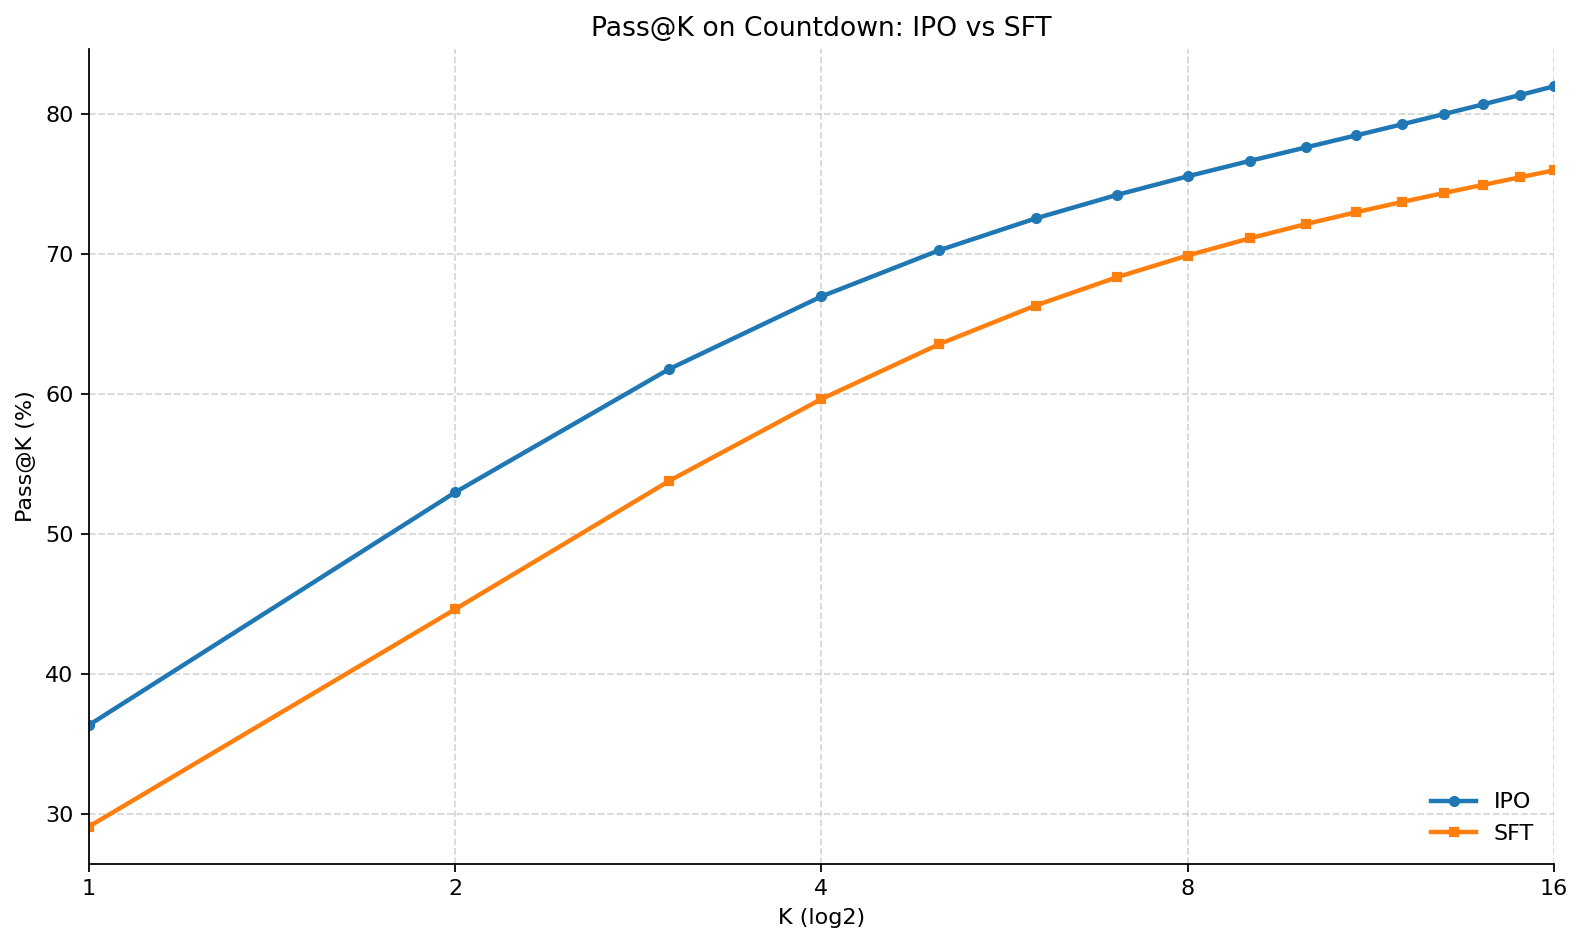

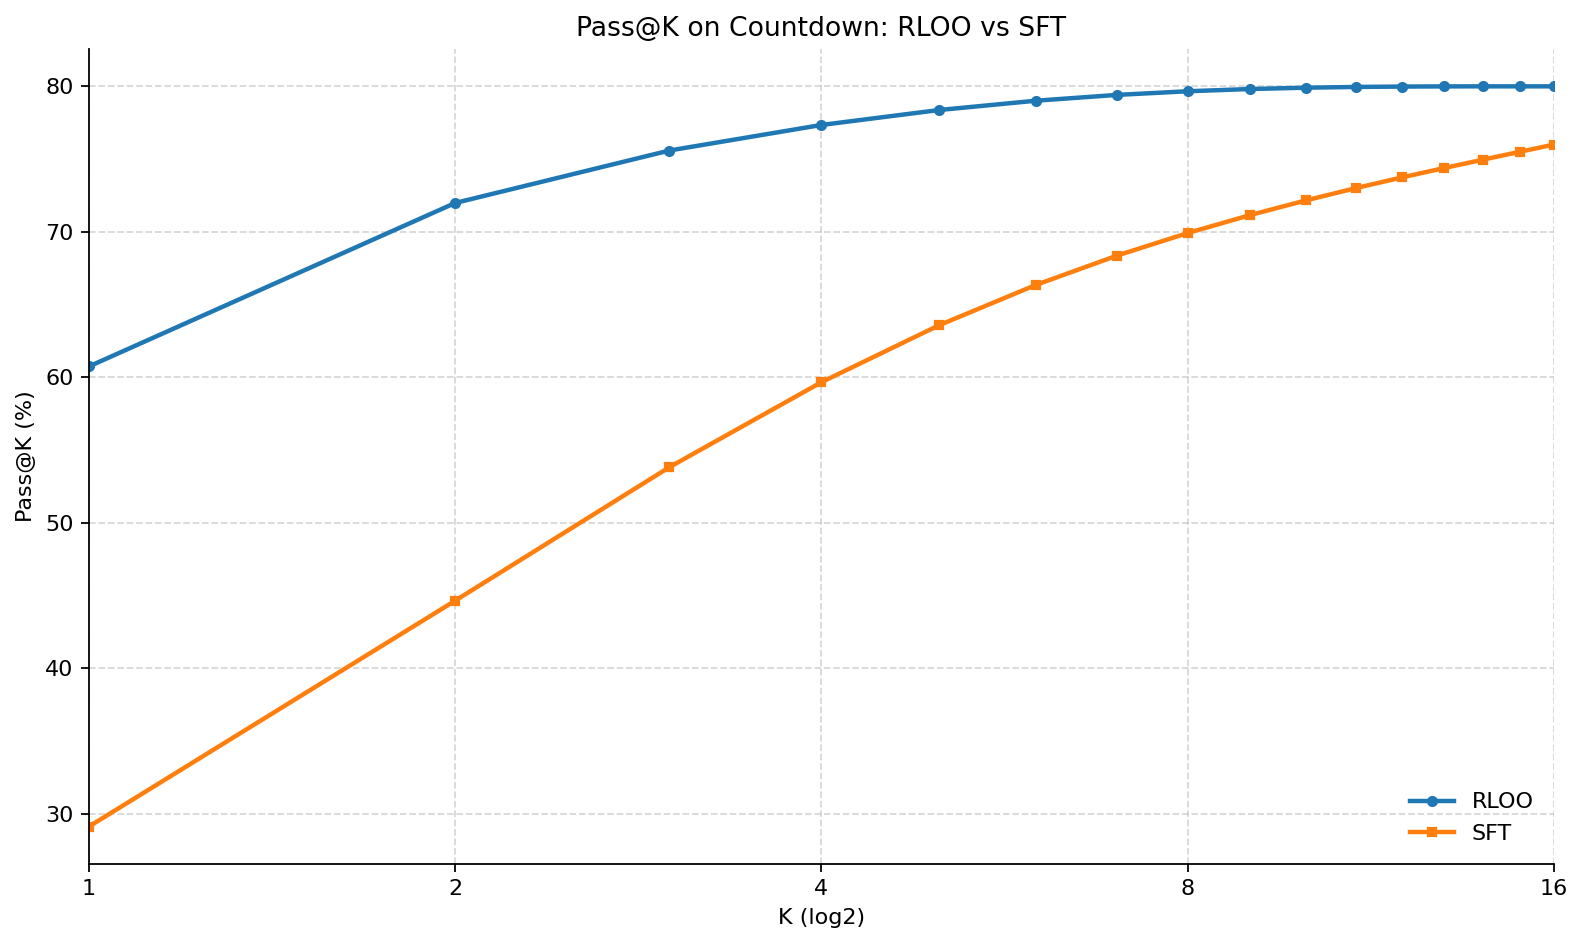

In [4]:
def plot_comparison(a_name, b_name, title):
    a, b = results[a_name], results[b_name]
    k = np.arange(1, len(a) + 1)

    fig, ax = plt.subplots(figsize=(10, 6), dpi=160)
    ax.plot(k, a * 100, marker="o", markersize=4, linewidth=2, label=a_name)
    ax.plot(k, b * 100, marker="s", markersize=4, linewidth=2, label=b_name)

    ax.set_xlabel("K (log2)")
    ax.set_ylabel("Pass@K (%)")
    ax.set_title(title)
    ax.set_xscale("log", base=2)
    ax.set_xlim(1, k[-1])

    major_ticks = [t for t in [1, 2, 4, 8, 16] if t <= k[-1]]
    ax.xaxis.set_major_locator(FixedLocator(major_ticks))
    ax.set_xticklabels([str(t) for t in major_ticks])

    ax.grid(True, which="major", linestyle="--", linewidth=0.8, alpha=0.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=False, loc="lower right")
    plt.tight_layout()
    plt.show()

plot_comparison("IPO", "SFT", "Pass@K on Countdown: IPO vs SFT")
plot_comparison("RLOO", "SFT", "Pass@K on Countdown: RLOO vs SFT")